# Facial Emotion Recognition on FER-2013

Classify 48x48 grayscale face images into 7 emotions: angry, disgust, fear, happy, neutral, sad and surprise. This notebook rebuilds my original CNN as a baseline, then improves it, then looks closely at where it still fails.

Run `python download_data.py` first to fetch the dataset into `data/`.

In [1]:
import io, os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")  # any Keras 3 backend works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import keras
from keras import layers
from sklearn.model_selection import train_test_split

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.15.1 | backend: torch


## 1. Load the data

FER-2013 comes with a 28,709-image training set and a 7,178-image test set. I hold out 10% of the training images (stratified) for validation, so the test set is only used once at the end.

In [2]:
def load(split):
    df = pd.read_parquet(f"data/{split}.parquet")
    x = np.stack([np.asarray(Image.open(io.BytesIO(b)).convert("L")) for b in df.img_bytes])[..., None]
    return x, df.labels.to_numpy().astype("int64")

x_all, y_all = load("train")
x_test, y_test = load("test")
x_train, x_val, y_train, y_val = train_test_split(x_all, y_all, test_size=0.1, stratify=y_all, random_state=42)
print(f"train {x_train.shape}  val {x_val.shape}  test {x_test.shape}")

train (25838, 48, 48, 1)  val (2871, 48, 48, 1)  test (7178, 48, 48, 1)


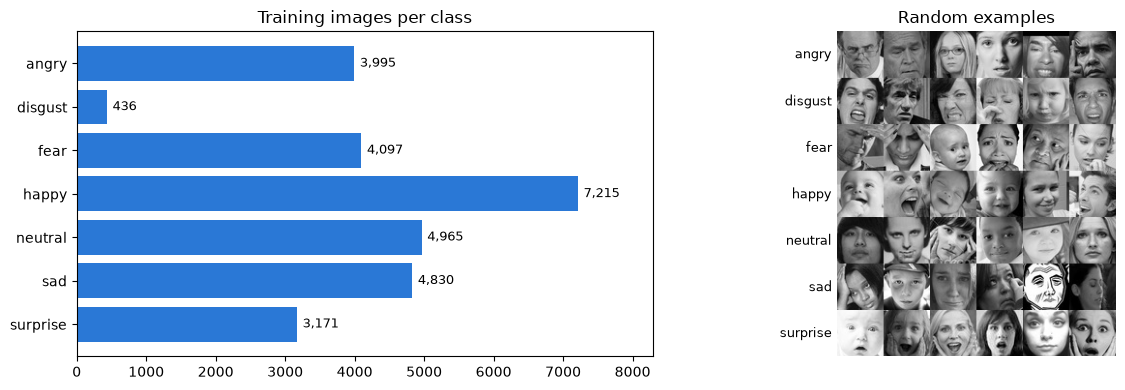

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})
counts = np.bincount(y_all, minlength=7)
ax1.barh(EMOTIONS, counts, color="#2a78d6")
for i, c in enumerate(counts):
    ax1.text(c + 80, i, f"{c:,}", va="center", fontsize=9)
ax1.invert_yaxis(); ax1.set_title("Training images per class"); ax1.set_xlim(0, counts.max() * 1.15)
ax2.axis("off")
rng = np.random.default_rng(0)
grid = np.vstack([np.hstack([x_all[rng.choice(np.where(y_all == k)[0])][..., 0] for _ in range(6)]) for k in range(7)])
ax2.imshow(grid, cmap="gray")
for k, name in enumerate(EMOTIONS):
    ax2.text(-6, k * 48 + 24, name, ha="right", va="center", fontsize=9)
ax2.set_title("Random examples")
plt.tight_layout(); plt.show()

The classes are very unbalanced: **disgust** has only 436 images, 16 times fewer than **happy**. The faces vary in pose, lighting and age, some are cartoons or partly covered, and the labels themselves are noisy (human agreement on FER-2013 is estimated at about 65%).

## 2. Baseline: my original CNN

Four convolution layers, two dropout layers and a 1,024-unit dense layer, trained for 10 epochs with Adam, as in my first version of this project.

In [4]:
def plot_history(histories):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        ax1.plot(h.history["accuracy"], label=f"{name} train")
        ax1.plot(h.history["val_accuracy"], "--", label=f"{name} validation")
        ax2.plot(h.history["loss"], label=f"{name} train")
        ax2.plot(h.history["val_loss"], "--", label=f"{name} validation")
    for ax, title in ((ax1, "Accuracy"), (ax2, "Loss")):
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.show()

baseline = keras.Sequential([
    keras.Input((48, 48, 1)),
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(1024, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(7, activation="softmax"),
], name="baseline")
baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 44, 44, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         7,175 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,345,607 (8.95 MB)

 Trainable params: 2,345,607 (8.95 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
hist_base = baseline.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=10, batch_size=64, verbose=2)

Epoch 1/10


404/404 - 43s - 106ms/step - accuracy: 0.2731 - loss: 1.7707 - val_accuracy: 0.3734 - val_loss: 1.6270


Epoch 2/10


404/404 - 43s - 106ms/step - accuracy: 0.4017 - loss: 1.5390 - val_accuracy: 0.4580 - val_loss: 1.4042


Epoch 3/10


404/404 - 43s - 107ms/step - accuracy: 0.4731 - loss: 1.3781 - val_accuracy: 0.5037 - val_loss: 1.2856


... (10 outputs left out)

Epoch 9/10


404/404 - 42s - 104ms/step - accuracy: 0.5961 - loss: 1.0671 - val_accuracy: 0.5859 - val_loss: 1.1044


Epoch 10/10


404/404 - 43s - 106ms/step - accuracy: 0.6078 - loss: 1.0380 - val_accuracy: 0.5852 - val_loss: 1.1063


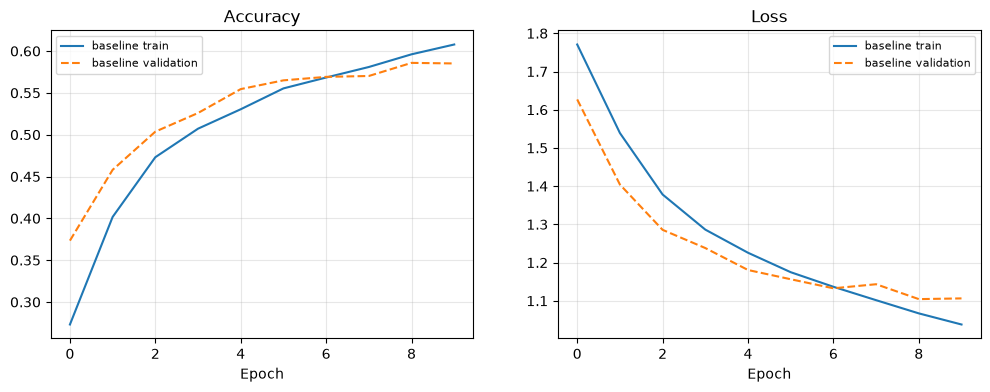

Baseline test accuracy: 59.2%


In [6]:
plot_history({"baseline": hist_base})
base_loss, base_acc = baseline.evaluate(x_test, y_test, verbose=0)
print(f"Baseline test accuracy: {base_acc:.1%}")

## 3. A better CNN

The baseline is still improving when it stops, and its training accuracy runs ahead of validation. Changes:

- **Four VGG-style blocks** (two 3x3 convolutions each, 64 → 512 filters) to learn richer features
- **Batch normalisation** after every convolution for faster, more stable training
- **Data augmentation**: horizontal flips, small rotations, zooms and shifts (a smiling face flipped is still smiling)
- **Global average pooling** instead of a huge `Flatten` → `Dense` layer
- **Learning-rate schedule and early stopping** on the validation set, so training runs as long as it helps

In [7]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

inputs = keras.Input((48, 48, 1))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.RandomTranslation(0.1, 0.1)(x)
x = layers.Rescaling(1 / 255)(x)
for filters in (64, 128, 256, 512):
    x = conv_block(x, filters)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(7, activation="softmax")(x)
model = keras.Model(inputs, outputs, name="emotion_cnn")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Parameters: {model.count_params():,}")

Parameters: 4,823,111


In [8]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
]
hist = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=50, batch_size=64,
                 callbacks=callbacks, verbose=2)

Epoch 1/50


404/404 - 269s - 665ms/step - accuracy: 0.2382 - loss: 1.8352 - val_accuracy: 0.2515 - val_loss: 1.8799 - learning_rate: 0.0010


Epoch 2/50


404/404 - 266s - 659ms/step - accuracy: 0.2712 - loss: 1.7623 - val_accuracy: 0.1700 - val_loss: 2.0467 - learning_rate: 0.0010


Epoch 3/50


404/404 - 275s - 681ms/step - accuracy: 0.3360 - loss: 1.6582 - val_accuracy: 0.2271 - val_loss: 1.8756 - learning_rate: 0.0010


... (60 outputs left out)

Epoch 34/50


404/404 - 219s - 542ms/step - accuracy: 0.6141 - loss: 1.0447 - val_accuracy: 0.6141 - val_loss: 1.0542 - learning_rate: 3.1250e-05


Epoch 35/50


404/404 - 219s - 542ms/step - accuracy: 0.6143 - loss: 1.0430 - val_accuracy: 0.6141 - val_loss: 1.0541 - learning_rate: 3.1250e-05


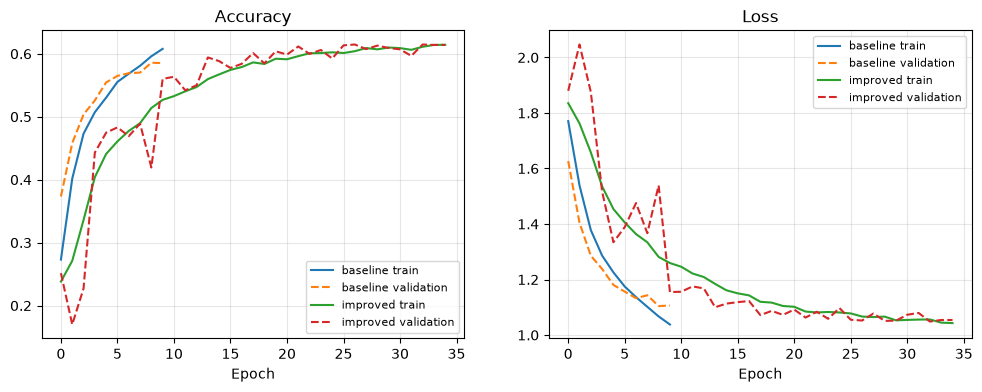

Baseline test accuracy: 59.2%
Improved test accuracy: 61.2%  (35 epochs)


In [9]:
plot_history({"baseline": hist_base, "improved": hist})
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline test accuracy: {base_acc:.1%}")
print(f"Improved test accuracy: {test_acc:.1%}  ({len(hist.history['loss'])} epochs)")

## 4. Where does it go wrong?

Accuracy hides a lot on an unbalanced dataset, so here is the per-class picture on the test set.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = model.predict(x_test, verbose=0)
pred = probs.argmax(1)
base_pred = baseline.predict(x_test, verbose=0).argmax(1)
print(classification_report(y_test, pred, target_names=EMOTIONS, digits=3))

              precision    recall  f1-score   support

       angry      0.496     0.575     0.532       958
     disgust      0.000     0.000     0.000       111
        fear      0.432     0.258     0.323      1024
       happy      0.863     0.841     0.852      1774
     neutral      0.555     0.636     0.593      1233
         sad      0.461     0.547     0.500      1247
    surprise      0.745     0.747     0.746       831

    accuracy                          0.612      7178
   macro avg      0.507     0.515     0.507      7178
weighted avg      0.603     0.612     0.603      7178



C:\Users\DHEERA~1\AppData\Local\Temp\claude\C--Users-Dheeransh\60207fa9-f812-42e1-b3f4-682023855642\scratchpad\venv-cifar\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\DHEERA~1\AppData\Local\Temp\claude\C--Users-Dheeransh\60207fa9-f812-42e1-b3f4-682023855642\scratchpad\venv-cifar\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\DHEERA~1\AppData\Local\Temp\claude\C--Users-Dheeransh\60207fa9-f812-42e1-b3f4-682023855642\scratchpad\venv-cifar\Lib\site-packages\sklearn\metrics\_c

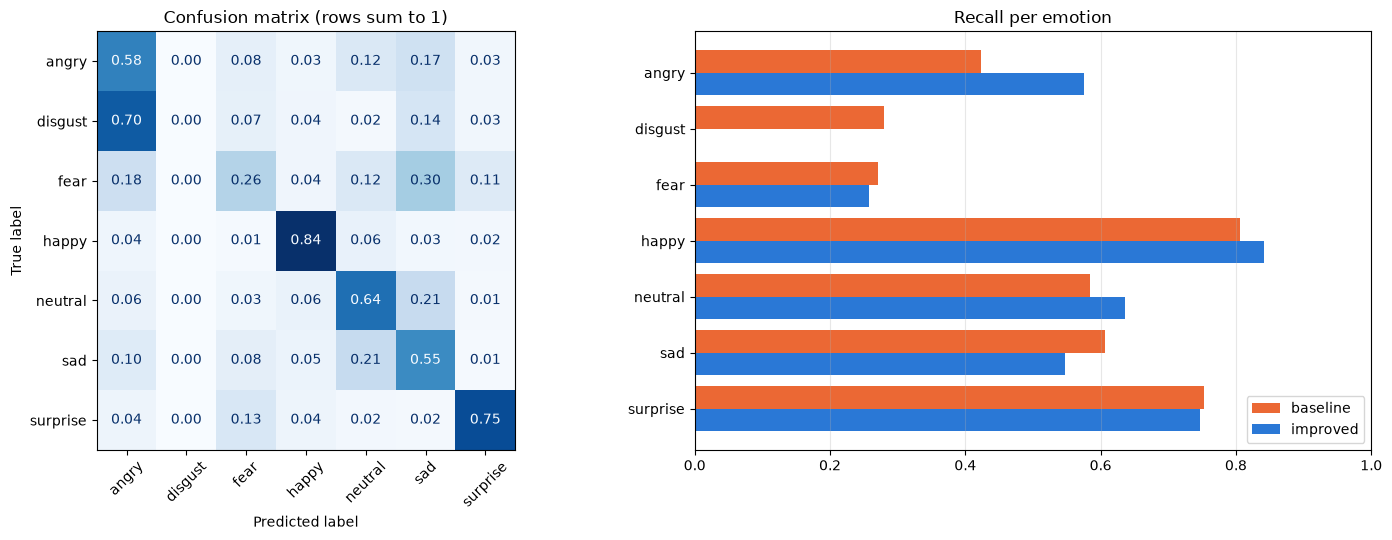

70% of disgust faces are predicted as angry
30% of fear faces are predicted as sad
21% of sad faces are predicted as neutral
21% of neutral faces are predicted as sad


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
cm = confusion_matrix(y_test, pred, normalize="true")
ConfusionMatrixDisplay(cm, display_labels=EMOTIONS).plot(ax=ax1, cmap="Blues", values_format=".2f", colorbar=False)
ax1.set_title("Confusion matrix (rows sum to 1)")
ax1.tick_params(axis="x", rotation=45)
recall_base = [(base_pred[y_test == k] == k).mean() for k in range(7)]
recall_new = [(pred[y_test == k] == k).mean() for k in range(7)]
ix = np.arange(7)
ax2.barh(ix - 0.2, recall_base, 0.4, label="baseline", color="#eb6834")
ax2.barh(ix + 0.2, recall_new, 0.4, label="improved", color="#2a78d6")
ax2.set_yticks(ix, EMOTIONS); ax2.invert_yaxis(); ax2.set_xlim(0, 1)
ax2.set_title("Recall per emotion"); ax2.legend(loc="lower right"); ax2.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:4], off.shape)):
    print(f"{off[i, j]:.0%} of {EMOTIONS[i]} faces are predicted as {EMOTIONS[j]}")

### The most confident mistakes

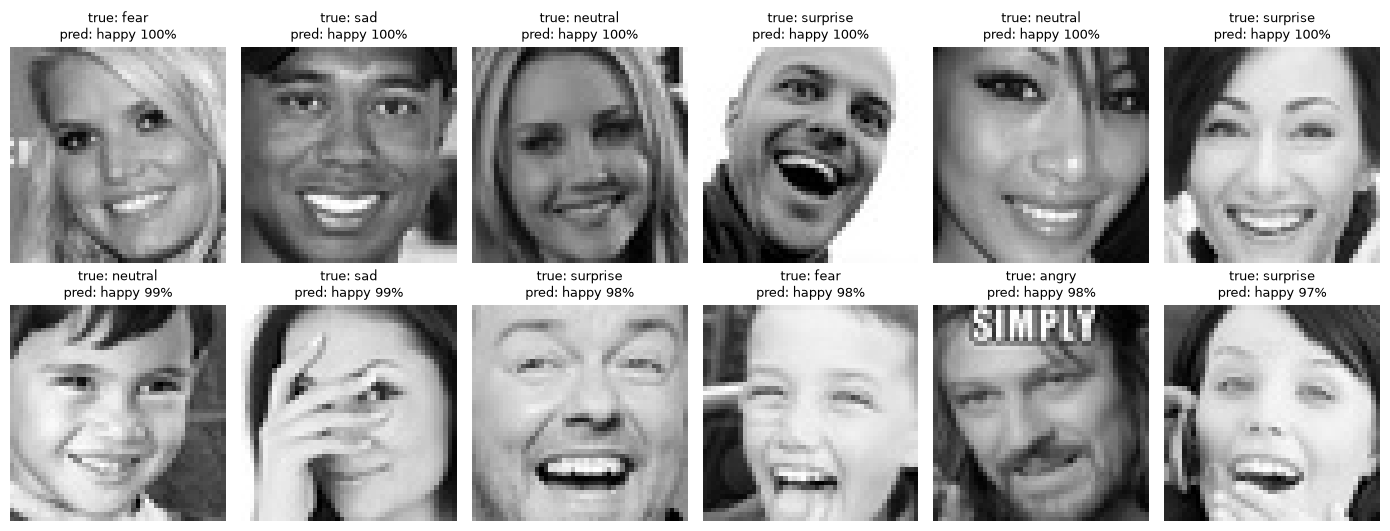

In [12]:
wrong = np.where(pred != y_test)[0]
worst = wrong[np.argsort(-probs[wrong].max(1))][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
for ax, i in zip(axes.flat, worst):
    ax.imshow(x_test[i, :, :, 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {EMOTIONS[y_test[i]]}\npred: {EMOTIONS[pred[i]]} {probs[i].max():.0%}", fontsize=9)
plt.tight_layout(); plt.show()

Several of these "mistakes" are debatable labels, which is the known ceiling of FER-2013: the dataset was labelled quickly from web images, and fear, sad, angry and neutral faces often look alike at 48x48.

In [13]:
model.save("emotion_cnn.keras")
print("Saved emotion_cnn.keras; use it with: python detect_emotions.py --source photo.jpg")

Saved emotion_cnn.keras; use it with: python detect_emotions.py --source photo.jpg
